In [32]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import warnings 
warnings.filterwarnings('ignore')

In [33]:
df = pd.read_csv("data.csv")

In [34]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [35]:
df.tail()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,Diesel,Individual,Manual,Second Owner
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,Diesel,Individual,Manual,Second Owner
4337,Maruti 800 AC BSIII,2009,110000,83000,Petrol,Individual,Manual,Second Owner
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,Diesel,Individual,Manual,First Owner
4339,Renault KWID RXT,2016,225000,40000,Petrol,Individual,Manual,First Owner


In [36]:
df.shape

(4340, 8)

In [37]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 271.4 KB


In [38]:
df.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [39]:
df.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

# Visualization

<Axes: xlabel='selling_price', ylabel='Count'>

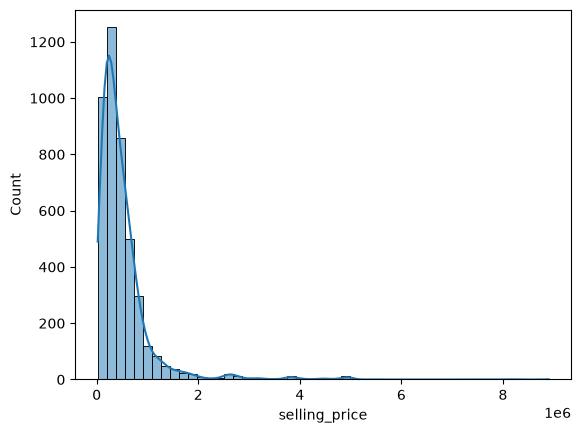

In [40]:
sns.histplot(df['selling_price'],bins = 50,kde=True)

<Axes: >

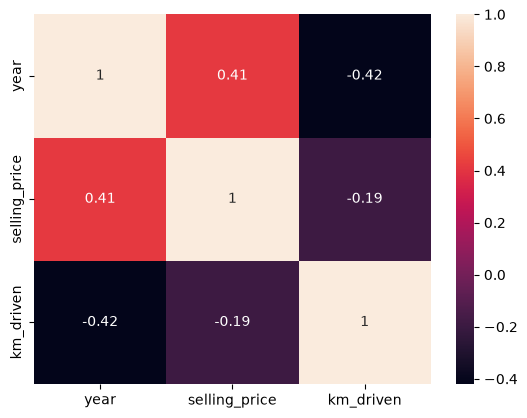

In [41]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

([0, 1, 2, 3, 4],
 [Text(0, 0, 'Petrol'),
  Text(1, 0, 'Diesel'),
  Text(2, 0, 'CNG'),
  Text(3, 0, 'LPG'),
  Text(4, 0, 'Electric')])

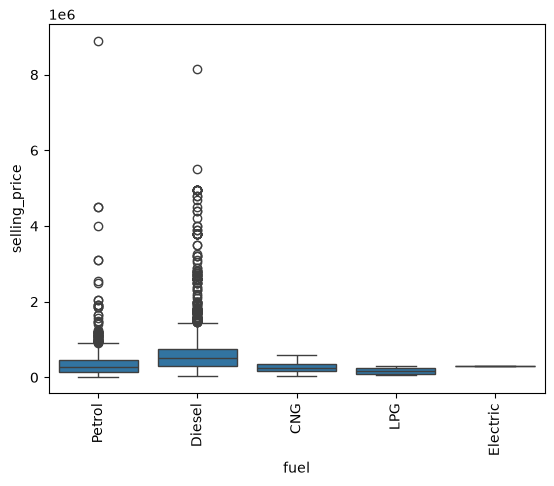

In [42]:
sns.boxplot(data = df, x = 'fuel', y = 'selling_price')
plt.xticks(rotation = 90)

In [43]:
X = df.drop(columns = ['selling_price'])
y = df['selling_price']

In [44]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='str')

In [45]:
X

,name,year,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,141000,Diesel,Individual,Manual,Second Owner
...,...,...,...,...,...,...,...
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,80000,Diesel,Individual,Manual,Second Owner
4336,Hyundai i20 Magna 1.4 CRDi,2014,80000,Diesel,Individual,Manual,Second Owner
4337,Maruti 800 AC BSIII,2009,83000,Petrol,Individual,Manual,Second Owner
4338,Hyundai Creta 1.6 CRDi SX Option,2016,90000,Diesel,Individual,Manual,First Owner


In [46]:
X_one_encode = pd.get_dummies(X,columns = ['name','transmission','fuel','seller_type','owner'],drop_first = True)

In [47]:
X_one_encode

,year,km_driven,name_Ambassador Classic 2000 Dsz,name_Ambassador Grand 1800 ISZ MPFI PW CL,name_Audi A4 1.8 TFSI,name_Audi A4 2.0 TDI,name_Audi A4 2.0 TDI 177 Bhp Premium Plus,name_Audi A4 3.0 TDI Quattro,name_Audi A4 30 TFSI Technology,name_Audi A4 35 TDI Premium,...,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,2007,70000,False,False,False,False,False,False,False,False,...,False,False,False,True,True,False,False,False,False,False
1,2007,50000,False,False,False,False,False,False,False,False,...,False,False,False,True,True,False,False,False,False,False
2,2012,100000,False,False,False,False,False,False,False,False,...,True,False,False,False,True,False,False,False,False,False
3,2017,46000,False,False,False,False,False,False,False,False,...,False,False,False,True,True,False,False,False,False,False
4,2014,141000,False,False,False,False,False,False,False,False,...,True,False,False,False,True,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4335,2014,80000,False,False,False,False,False,False,False,False,...,True,False,False,False,True,False,False,True,False,False
4336,2014,80000,False,False,False,False,False,False,False,False,...,True,False,False,False,True,False,False,True,False,False
4337,2009,83000,False,False,False,False,False,False,False,False,...,False,False,False,True,True,False,False,True,False,False
4338,2016,90000,False,False,False,False,False,False,False,False,...,True,False,False,False,True,False,False,False,False,False


In [48]:
X_one_encode = X_one_encode.astype(int)

In [49]:
X_one_encode

,year,km_driven,name_Ambassador Classic 2000 Dsz,name_Ambassador Grand 1800 ISZ MPFI PW CL,name_Audi A4 1.8 TFSI,name_Audi A4 2.0 TDI,name_Audi A4 2.0 TDI 177 Bhp Premium Plus,name_Audi A4 3.0 TDI Quattro,name_Audi A4 30 TFSI Technology,name_Audi A4 35 TDI Premium,...,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,2007,70000,0,0,0,0,0,0,0,0,...,0,0,0,1,1,0,0,0,0,0
1,2007,50000,0,0,0,0,0,0,0,0,...,0,0,0,1,1,0,0,0,0,0
2,2012,100000,0,0,0,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0,0
3,2017,46000,0,0,0,0,0,0,0,0,...,0,0,0,1,1,0,0,0,0,0
4,2014,141000,0,0,0,0,0,0,0,0,...,1,0,0,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4335,2014,80000,0,0,0,0,0,0,0,0,...,1,0,0,0,1,0,0,1,0,0
4336,2014,80000,0,0,0,0,0,0,0,0,...,1,0,0,0,1,0,0,1,0,0
4337,2009,83000,0,0,0,0,0,0,0,0,...,0,0,0,1,1,0,0,1,0,0
4338,2016,90000,0,0,0,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0,0


In [57]:
from sklearn.preprocessing import LabelEncoder
columns = ['name','transmission','fuel','seller_type','owner']
Xlabel = X.copy()
label_encoder = {}

for col in columns:
    le = LabelEncoder()
    Xlabel[col] = le.fit_transform(Xlabel[col].astype(str))
    label_encoder[col] = le


In [61]:
from sklearn.preprocessing import StandardScaler

numerical_cols = ['year', 'km_driven']
scaler = StandardScaler()
X_one_encode[numerical_cols] = scaler.fit_transform(X_one_encode[numerical_cols])

In [62]:
Xlabel[['name','transmission','fuel','seller_type','owner']] = scaler.fit_transform(Xlabel[['name','transmission','fuel','seller_type','owner']])

In [63]:
Xlabel 

,name,year,km_driven,fuel,seller_type,transmission,owner
0,0.058522,2007,70000,1.014993,0.448192,0.339276,-0.665079
1,0.723520,2007,50000,1.014993,0.448192,0.339276,-0.665079
2,-0.616477,2012,100000,-0.974051,0.448192,0.339276,-0.665079
3,-1.583975,2017,46000,1.014993,0.448192,0.339276,-0.665079
4,-1.181476,2014,141000,-0.974051,0.448192,0.339276,0.956519
...,...,...,...,...,...,...,...
4335,-0.373977,2014,80000,-0.974051,0.448192,0.339276,0.956519
4336,-0.376477,2014,80000,-0.974051,0.448192,0.339276,0.956519
4337,0.063522,2009,83000,1.014993,0.448192,0.339276,0.956519
4338,-0.926476,2016,90000,-0.974051,0.448192,0.339276,-0.665079


In [64]:
X_one_encode

,year,km_driven,name_Ambassador Classic 2000 Dsz,name_Ambassador Grand 1800 ISZ MPFI PW CL,name_Audi A4 1.8 TFSI,name_Audi A4 2.0 TDI,name_Audi A4 2.0 TDI 177 Bhp Premium Plus,name_Audi A4 3.0 TDI Quattro,name_Audi A4 30 TFSI Technology,name_Audi A4 35 TDI Premium,...,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,-1.445074,0.081139,0,0,0,0,0,0,0,0,...,0,0,0,1,1,0,0,0,0,0
1,-1.445074,-0.347689,0,0,0,0,0,0,0,0,...,0,0,0,1,1,0,0,0,0,0
2,-0.258795,0.724381,0,0,0,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0,0
3,0.927485,-0.433455,0,0,0,0,0,0,0,0,...,0,0,0,1,1,0,0,0,0,0
4,0.215717,1.603479,0,0,0,0,0,0,0,0,...,1,0,0,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4335,0.215717,0.295553,0,0,0,0,0,0,0,0,...,1,0,0,0,1,0,0,1,0,0
4336,0.215717,0.295553,0,0,0,0,0,0,0,0,...,1,0,0,0,1,0,0,1,0,0
4337,-0.970563,0.359877,0,0,0,0,0,0,0,0,...,0,0,0,1,1,0,0,1,0,0
4338,0.690229,0.509967,0,0,0,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0,0


In [65]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [66]:
X_train, X_test, y_train, y_test = train_test_split(X_one_encode, y, test_size=0.33, random_state=42)
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1503,)","[108252.26,-27365.01, 43979.05,...,-20559. , 61238.39,-28222.88]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1503,)","['year','km_driven','name_Ambassador Classic 2000 Dsz',..., 'owner_Second Owner','owner_Test Drive Car','owner_Third Owner']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.17e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1503
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1224)


In [70]:
y

0        60000
1       135000
2       600000
3       250000
4       450000
         ...  
4335    409999
4336    409999
4337    110000
4338    865000
4339    225000
Name: selling_price, Length: 4340, dtype: int64

In [69]:
y_pred = model.predict(X_test)
y_pred

array([251374.10754642, 447659.16862383,  96474.5518091 , ...,
       350348.78780029, 647885.16042333, 538807.20938858], shape=(1433,))

In [71]:
r2 = r2_score(y_test,y_pred)
r2

0.7008392638127441

In [72]:
n = X_test.shape[0]
p = X_test.shape[1]
adjusted_r2 = 1 - ((1 - r2) * (n - 1)) / (n - p - 1)
print("Adjusted R² Score:", adjusted_r2)

Adjusted R² Score: 7.03377710169226


In [74]:
X_train, X_test, y_train, y_test = train_test_split(Xlabel, y, test_size=0.33, random_state=42)
model2 = LinearRegression()
model2.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ -8971.04, 36857.06, -1.03,..., -4318.36,-266187.12, -17923.21]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['name','year','km_driven',...,'seller_type','transmission','owner']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-7.363e+07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [75]:

y_pred = model2.predict(X_test)
y_pred

array([422520.64288644, 524298.71271177,  89961.48553678, ...,
       433994.7556438 , 712044.75108764, 444699.24880397], shape=(1433,))

In [76]:
y_test

3978     165000
1448     250000
2664     120000
17       450000
1634     730000
         ...   
572     3800000
4278     614000
288      350000
1615     600000
2330     540000
Name: selling_price, Length: 1433, dtype: int64

In [77]:
r2 = r2_score(y_test,y_pred)
r2

0.448312497042599